In [21]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

Visualize for highest paying skills

In [22]:
# Only get data Analyst jobs in the US
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country']=='United States')].copy()
# Drop NAN values from 'salary_year_avg' column for accurate visualisation
df_DA_US = df_DA_US.dropna(subset =['salary_year_avg'])


In [23]:
#explod out the column skill
df_DA_US = df_DA_US.explode('job_skills')
df_DA_US[['job_skills' , 'salary_year_avg']].head(5)


,job_skills,salary_year_avg
109,python,89000.0
109,r,89000.0
109,alteryx,89000.0
109,tableau,89000.0
180,excel,90250.0


In [24]:
#Get the highest paying skills (order by highest to lowest)
df_DA_US_pay =df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count' , 'median']).sort_values(by ='median' , ascending = False)
df_DA_top_pay= df_DA_US_pay.head(10)
df_DA_top_pay

,count,median
job_skills,,
dplyr,2,196250.0
bitbucket,3,189000.0
gitlab,3,186000.0
solidity,1,179000.0
hugging face,1,175000.0
couchbase,1,160515.0
ansible,1,159640.0
mxnet,2,149000.0
cassandra,6,148250.0


In [25]:
#get the highest paying skills (order by highest to lowest)
df_DA_skills = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count', 'median']).sort_values(by ='count', ascending = False)
df_DA_skills =df_DA_skills.head(10).sort_values(by='median', ascending=False)
df_DA_skills

,count,median
job_skills,,
python,1431,97500.00
tableau,1364,92875.00
r,893,92500.00
sql server,286,92500.00
sql,2508,91000.00
sas,926,90000.00
power bi,838,90000.00
powerpoint,462,85000.00
excel,1808,84392.00


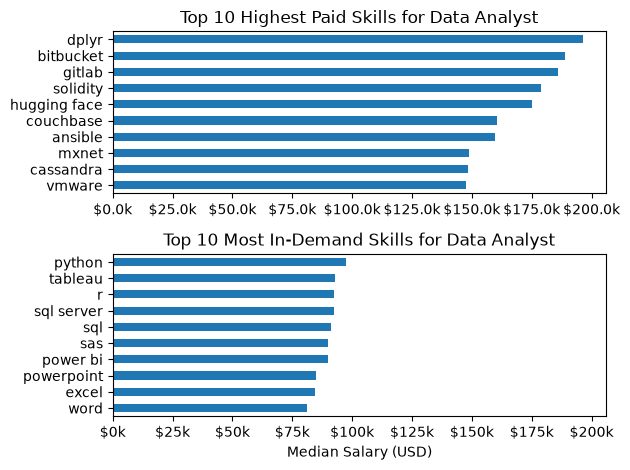

In [26]:
fig , ax = plt.subplots(2, 1)

# Top 10 Highest Paid Skills for Data Analyst
df_DA_top_pay.plot(kind= 'barh' ,y='median', ax=ax[0], legend = False)
ax[0].set_title('Top 10 Highest Paid Skills for Data Analyst')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].invert_yaxis()
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x , pos : f'${(int(x)/1000)}k'))
# Top 10 Most In-Demand Skills for Data Analyst
df_DA_skills[::-1].plot(kind= 'barh' ,y='median', ax=ax[1], legend = False)
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analyst')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary (USD)')
ax[1].set_xlim(ax[0].get_xlim())  # Set the same x-axis limits as the first plot
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x , pos : f'${int(x/1000)}k'))

plt.tight_layout()
plt.show()